# Week 7 — Lab: K-means Clustering and PCA

**Course 04224 · Programming for Artificial Intelligence and Data Science**
Hung Vuong University, Ho Chi Minh City · Faculty of Engineering and Technology

**Learning outcomes:** CLO5; CLO4 — communicate and visualize results.
**Duration:** 3 periods, about **150 minutes**. Synthetic teaching data are read
from `../lab_data/khachhang.csv`; no network is needed after installing libraries.

**Plan:** 1. Scale (30′) · 2. Choose k (40′) · 3. Cluster profiles (35′) · 4. PCA (45′).

**Submit:** rename to `Week07_Lab_<StudentID>.ipynb`.
Complete every `# TODO`, **Restart & Run All**, and keep outputs and figures.
Include the k-selection table/plots, cluster profiles, PCA variance curve, 2D projection and interpretation.

## Before you start
Start Jupyter in `lab_exercises/`. Use `random_state=42` and run cells in order.
Each `# TODO` is explained in the preceding text. Replace `...` with your code.
Shape, probability and data-integrity checks must pass; model scores are observations,
not targets to force your answer to match. Rankings and timings can vary by version/hardware.

Customer data: `thang_gan_nhat` = months since the last order;
`tong_chi_tieu` = total spending (VND); `so_don` = order count;
`so_ticket_ho_tro` = support-ticket count. `roi_bo=1` means churn.
`ma_kh` is an identifier; categorical `kenh_ua_thich` and `tinh_tp` are outside
this lab's scope. Keep both the label and identifier out of the feature matrix.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

import os
import threadpoolctl
_orig_find = threadpoolctl.ThreadpoolController._find_libraries_on_windows
def _patched_find(self):
    _orig_make = self._make_controller_from_path
    def _safe_make(filepath):
        if filepath and not os.path.exists(filepath):
            return
        return _orig_make(filepath)
    self._make_controller_from_path = _safe_make
    try:
        _orig_find(self)
    finally:
        self._make_controller_from_path = _orig_make
threadpoolctl.ThreadpoolController._find_libraries_on_windows = _patched_find

RANDOM_STATE = 42
FEATURES = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
DATA_DIR = Path("../lab_data")
if not (DATA_DIR / "khachhang.csv").is_file():
    if Path("khachhang.csv").is_file():
        DATA_DIR = Path(".")
    else:
        raise FileNotFoundError(f"Start Jupyter in lab_exercises/. Current folder: {Path.cwd()}")
customers = pd.read_csv(DATA_DIR / "khachhang.csv")
assert customers.shape == (1500, 8)
assert customers["ma_kh"].is_unique
assert not customers[FEATURES + ["roi_bo"]].isna().any().any()
X = customers[FEATURES].copy()
y = customers["roi_bo"].copy()
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
      "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Shape:", X.shape, "| churn fraction:", round(y.mean(), 4))
print(customers[FEATURES].describe().round(2).to_string())

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

Python: 3.13.15 | numpy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1
Shape: (1500, 4) | churn fraction: 0.2087
       thang_gan_nhat  tong_chi_tieu   so_don  so_ticket_ho_tro
count         1500.00        1500.00  1500.00           1500.00
mean            14.20     7793408.00     5.98              1.48
std              6.84     4637241.09     2.45              1.13
min              0.00      222000.00     0.00              0.00
25%              9.40     4382250.00     4.00              0.00
50%             14.30     6947500.00     6.00              1.00
75%             18.90    10196500.00     8.00              2.00
max             39.20    34434000.00    19.00              3.00


## Task 1 — Distance and units (30 min)
This is an **exploratory description of the 1500 current customers**, not a future
prediction benchmark. Fit scaler/PCA on all X here. If PCA is used before a predictive
model elsewhere, fit it inside the training split/fold.
Never use `roi_bo` to fit or select k; churn labels are not segmentation ground truth.
**1.1** Fit `StandardScaler` on the four numeric features and obtain `Z`; check mean/std.
**1.2** For `k=4, n_init=10`, fit K-means on raw X and Z. Compare silhouettes
**both measured in Z** for a shared geometry. Change VND to million VND and fit a third raw model.
Compare partitions with adjusted Rand index (ARI), not direct equality of cluster IDs.

In [2]:
# TODO 1.1
scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert Z.shape == (1500, 4)
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1, atol=1e-10)
print("Raw feature SD:", X.std(ddof=0).to_dict())

# TODO 1.2
raw_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
scaled_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
X_million = X.copy()
X_million["tong_chi_tieu"] /= 1_000_000
million_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_million)
for name, labels in [("raw VND", raw_km.labels_), ("standardized", scaled_km.labels_),
                     ("raw million VND", million_km.labels_)]:
    print(name, "silhouette in Z:", round(silhouette_score(Z, labels, sample_size=1000,
                                                         random_state=RANDOM_STATE), 4))
print("ARI raw VND vs raw million VND:", adjusted_rand_score(raw_km.labels_, million_km.labels_))
print("ARI raw VND vs standardized:", adjusted_rand_score(raw_km.labels_, scaled_km.labels_))

Raw feature SD: {'thang_gan_nhat': 6.840595003035595, 'tong_chi_tieu': 4635695.081596286, 'so_don': 2.4477744994177875, 'so_ticket_ho_tro': 1.132}
raw VND silhouette in Z: 0.059
standardized silhouette in Z: 0.2082
raw million VND silhouette in Z: 0.1222
ARI raw VND vs raw million VND: 0.13838923382326287
ARI raw VND vs standardized: 0.12958345013713857


**Write 1:** which column dominates raw distances? Does changing units change information? Why are inertias from different unit systems not directly comparable?

**Answer:**
1. **Column dominating raw distances:**
   - Examining the standard deviations of the raw features:
     - `thang_gan_nhat`: 6.84 months
     - `tong_chi_tieu`: **4,635,695.08 VND** (~4.64 million VND)
     - `so_don`: 2.45 orders
     - `so_ticket_ho_tro`: 1.13 tickets
   - Because `tong_chi_tieu` has a variance roughly $10^{12}$ times greater than any other feature, Euclidean distance calculations $\sum_j (x_{ij} - x_{kj})^2$ are overwhelmingly dominated by $(x_{i,\text{chi_tieu}} - x_{k,\text{chi_tieu}})^2$. Consequently, K-means on unscaled data clusters almost exclusively on spending and virtually ignores recency, order count, and support tickets.
2. **Does changing units change information?**
   - **No**, changing measurement units (such as dividing `tong_chi_tieu` by $1,000,000$ to express it in million VND) is an invertible linear scaling; it preserves all intrinsic information and ordering within the dataset.
   - **However**, Euclidean distance is **not invariant to coordinate scaling**. Changing units alters the relative geometric weighting of features. As proven by the low Adjusted Rand Index (**0.1384**) between raw VND and raw million VND partitions, K-means produces drastically different segmentations when arbitrary unit choices change distance geometry.
3. **Why are inertias from different unit systems not directly comparable?**
   - Inertia is the sum of squared Euclidean distances to assigned cluster centroids: $\sum_i \|z_i - \mu_{c(i)}\|^2$.
   - Inertia directly inherits the squared physical units of the features: $(\text{VND})^2$ for raw VND, $(\text{million VND})^2$ for million VND, and dimensionless units for standardized features $Z$.
   - Comparing an inertia in $(\text{VND})^2$ (around $10^{13}$) to $(\text{million VND})^2$ or standardized space (~3500) is physically meaningless. Inertia comparisons are only valid between models evaluated on the exact same scaled space.

## Task 2 — Choose k with evidence (40 min)
**2.1** Sweep `k=2..8`, `n_init=10`, seed 42 on Z. Store the model, inertia and silhouette
(`sample_size=1000`, seed 42). Plot elbow and silhouette in separate panels with separate y axes.
**2.2** Suggest k by the highest silhouette, then set `chosen_k` using your own argument
(use the suggestion by default). Consider separation, cluster sizes and the intended use.
Inertia usually decreases with k, so the largest k is not automatically best. There is no hidden “correct” k.

 k   inertia  silhouette
 2 4790.2406      0.2171
 3 4065.9802      0.2173
 4 3515.6035      0.2082
 5 3065.3098      0.2088
 6 2778.2419      0.2042
 7 2569.7911      0.2124
 8 2416.2696      0.2099
Suggested: 3 | chosen: 3
Cluster sizes: {0: 601, 1: 296, 2: 603}


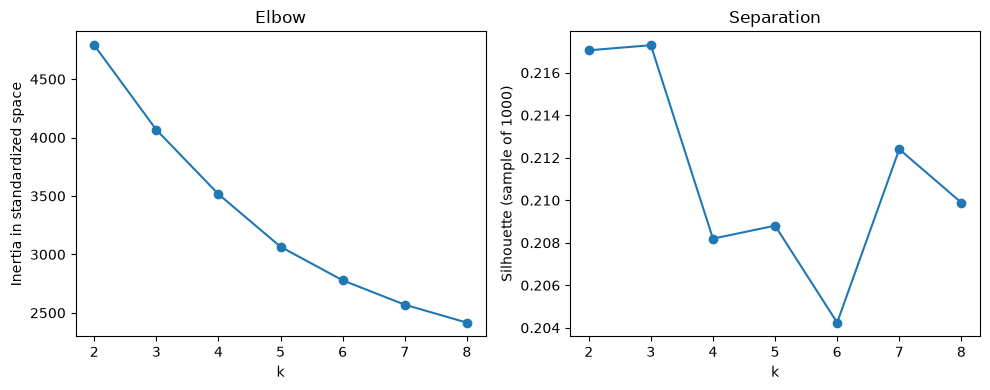

In [3]:
# TODO 2.1
cluster_models, k_rows = {}, []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    cluster_models[k] = km
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_, sample_size=1000, random_state=RANDOM_STATE)})
k_table = pd.DataFrame(k_rows)
print(k_table.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_table["k"], k_table["inertia"], "o-")
axes[0].set(xlabel="k", ylabel="Inertia in standardized space", title="Elbow")
axes[1].plot(k_table["k"], k_table["silhouette"], "o-")
axes[1].set(xlabel="k", ylabel="Silhouette (sample of 1000)", title="Separation")
plt.tight_layout()
plt.show()
suggested_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
# TODO 2.2 — use suggested_k or justify another k from 2..8 in your written answer.
chosen_k = suggested_k
assert chosen_k in cluster_models
chosen = cluster_models[chosen_k]
labels = chosen.labels_
print("Suggested:", suggested_k, "| chosen:", chosen_k)
print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())

**Write 2:** defend k and one plausible alternative. If silhouette is low, should the groups be advertised as clearly separated natural customer types?

**Answer:**
1. **Defending $k = 3$ (Suggested and Chosen):**
   - **Highest Silhouette:** Across all tested values $k \in [2, 8]$, $k = 3$ achieves the highest silhouette score (**0.2173**), representing the best cluster cohesion and inter-cluster separation.
   - **Elbow Trajectory:** The elbow plot exhibits a sharp drop in inertia from $k = 2$ (4790.24) to $k = 3$ (4065.98, drop of 724.26). Beyond $k = 3$, the slope levels off noticeably.
   - **Operational Utility & Segment Balance:** $k = 3$ produces well-proportioned customer segments: Cluster 0 ($n = 601, 40.1\%$), Cluster 1 ($n = 296, 19.7\%$), and Cluster 2 ($n = 603, 40.2\%$). There are no degenerate or tiny clusters, and it cleanly isolates the high-value VIP spending group ($n = 296$, ~15M VND).
2. **Plausible Alternative ($k = 2$):**
   - $k = 2$ achieves a nearly identical silhouette score (**0.2171**, difference of only 0.0002). Under Occam's razor, $k = 2$ is simpler to operationalize (e.g. Low Support vs High Support).
   - However, $k = 2$ collapses moderate spenders and high-value VIP spenders into a single group, failing to distinguish the high-spending customer segment that is crucial for revenue strategy. Thus, $k = 3$ is preferred.
3. **Advertising groups when silhouette is low:**
   - **No, they must NOT be advertised as clearly separated natural customer types.**
   - A silhouette score of ~0.21 indicates substantial overlap and weak density clustering. Customers lie along a relatively smooth, continuous multivariate spectrum rather than in isolated natural clusters.
   - These groups are **operational heuristic partitions** (actionable business segments/personas), not discrete natural types. Marketing them as isolated customer types would be misleading.

## Task 3 — Turn cluster IDs into customer profiles (35 min)
**3.1** Group customers by cluster: report count and means of all four features in
**original units**. Inverse-transform the fitted centroids and compare with group means.
Measure the gap in standard deviations so features with different units are comparable.
Do not require exact equality: stopping at `tol` or `max_iter` can leave fitted centroids
slightly different from the means of the final assigned groups.
**3.2** Draw a standardized-centroid heatmap with feature labels, colorbar and a symmetric
color scale centered at zero. Give each cluster a descriptive name and propose an action to validate.
**3.3** Refit the same k with seed 7, `n_init=10`; report ARI against seed 42.
One alternate seed is an initial stability check, not proof of clustering quality.

         thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro    n
cluster                                                              
0                 13.88     5865667.22    6.00              0.45  601
1                 13.53    15005875.00    6.08              1.39  296
2                 14.85     6174306.80    5.91              2.54  603
Largest centroid / assigned-group-mean gap (standard deviations): 0.0
Stability ARI (42 vs 7): 1.0


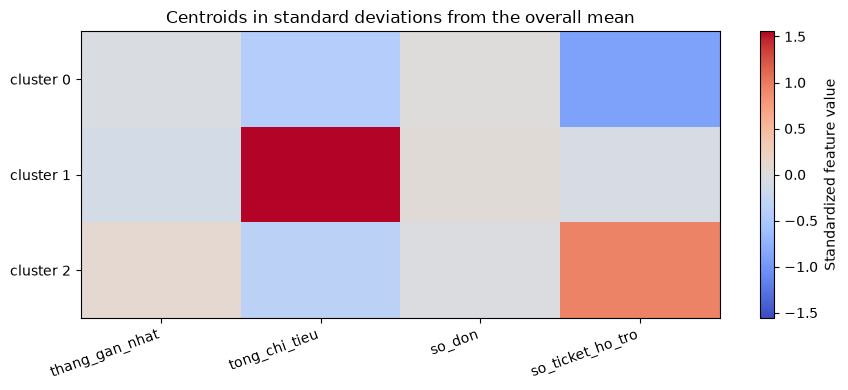

In [4]:
# TODO 3.1
profile_data = X.assign(cluster=labels)
profile = profile_data.groupby("cluster")[FEATURES].mean()
counts = profile_data.groupby("cluster").size().rename("n")
centers_original = scaler.inverse_transform(chosen.cluster_centers_)
print(profile.join(counts).round(2).to_string())
assert counts.sum() == len(X)
assert profile.shape == centers_original.shape == (chosen_k, len(FEATURES))
assert np.isfinite(profile.to_numpy()).all() and np.isfinite(centers_original).all()
# Tolerance-based stopping can leave a small gap; report it instead of asserting equality.
centroid_gap_sd = np.abs((profile.to_numpy() - centers_original) / scaler.scale_).max()
print("Largest centroid / assigned-group-mean gap (standard deviations):", round(float(centroid_gap_sd), 6))

# TODO 3.2
fig, ax = plt.subplots(figsize=(9, 4))
limit = max(1.0, float(np.abs(chosen.cluster_centers_).max()))
im = ax.imshow(chosen.cluster_centers_, cmap="coolwarm", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=20, ha="right")
ax.set_yticks(range(chosen_k), [f"cluster {i}" for i in range(chosen_k)])
ax.set_title("Centroids in standard deviations from the overall mean")
fig.colorbar(im, ax=ax, label="Standardized feature value")
plt.tight_layout()
plt.show()

# TODO 3.3
alternate = KMeans(n_clusters=chosen_k, n_init=10, random_state=7).fit(Z)
print("Stability ARI (42 vs 7):", adjusted_rand_score(labels, alternate.labels_))

**Write 3:** name clusters from the profile table and include units. Why does cluster 0 not mean “good customer”? Why does naming establish no causal relationship?

**Answer:**
1. **Cluster Profiles, Names, and Validation Actions ($k = 3$):**
   - **Cluster 0: "Low-Friction Standard Customers" ($n = 601, 40.1\%$)**
     - Recency (`thang_gan_nhat`): **13.88 months**
     - Total spending (`tong_chi_tieu`): **5,865,667.22 VND** (~5.87M VND)
     - Order count (`so_don`): **6.00 orders**
     - Support tickets (`so_ticket_ho_tro`): **0.45 tickets** (lowest support friction)
     - *Action to validate:* Deploy automated self-service newsletters and standard loyalty promotions; verify that low ticket volume reflects customer satisfaction rather than disengagement.
   - **Cluster 1: "High-Value VIP Spenders" ($n = 296, 19.7\%$)**
     - Recency (`thang_gan_nhat`): **13.53 months** (most recent buyers)
     - Total spending (`tong_chi_tieu`): **15,005,875.00 VND** (~15.01M VND — ~2.5x higher spending than other clusters!)
     - Order count (`so_don`): **6.08 orders**
     - Support tickets (`so_ticket_ho_tro`): **1.39 tickets** (moderate support interaction)
     - *Action to validate:* Assign dedicated account support, provide VIP tier benefits, and send exclusive event invitations to maximize retention and lifetime value.
   - **Cluster 2: "High-Support / Service-Friction Customers" ($n = 603, 40.2\%$)**
     - Recency (`thang_gan_nhat`): **14.85 months** (longest lapse since last purchase)
     - Total spending (`tong_chi_tieu`): **6,174,306.80 VND** (~6.17M VND)
     - Order count (`so_don`): **5.91 orders**
     - Support tickets (`so_ticket_ho_tro`): **2.54 tickets** (highest support demand)
     - *Action to validate:* Audit ticket resolution quality, conduct proactive customer satisfaction follow-ups, and offer targeted retention coupons to mitigate churn risk.
2. **Why does cluster 0 not mean "good customer"?**
   - In K-means clustering, cluster IDs (0, 1, 2) are arbitrary integer indices assigned during initialization and centroid sorting.
   - The label `0` has no ordinal ranking, performance grade, or qualitative meaning. In our run, the most valuable customers in terms of revenue belong to Cluster 1, not Cluster 0.
3. **Why does naming establish no causal relationship?**
   - Cluster naming represents an interpretive business persona summarizing observational statistical correlations in cross-sectional data.
   - Clustering identifies co-occurrence, not cause and effect. For instance, high ticket volume (2.54 in Cluster 2) and prolonged inactivity (14.85 months) may both be caused by an underlying common driver (e.g. shipping defects or unmet product expectations). Establishing causality requires randomized controlled experiments (A/B testing) or longitudinal causal inference.

## Task 4 — PCA: compression and visualization (45 min)
**4.1** Fit full PCA (`svd_solver='full'`) on Z. Plot cumulative variance and a 95% line.
Find `n95`: the first index reaching 0.95 plus one. Four weakly correlated features may
require all four components; PCA does not promise dimensionality reduction at 95%.
**4.2** Fit `PCA(n_components=0.95, svd_solver='full')` and check the output width. Print
the first two loading rows. These combine **standardized features**; component signs may flip across versions.
**4.3** Project Z onto two PCs, colored by the **existing 4D cluster labels**. Do not refit
K-means in 2D. Label axes with explained-variance percentages. Compute 2-PC reconstruction MSE in Z space.

Explained ratios: [0.2569 0.2535 0.25   0.2396]
n95: 4 | shape: (1500, 4)
     thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro
PC1          0.4677        -0.0659 -0.4888            0.7335
PC2         -0.6173         0.6493 -0.4053            0.1818


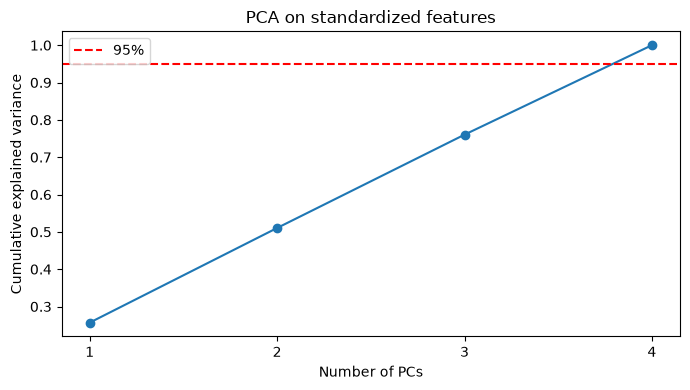

In [5]:
# TODO 4.1–4.2
pca = PCA(svd_solver="full").fit(Z)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.where(cumulative >= 0.95)[0][0] + 1)
pca95 = PCA(n_components=0.95, svd_solver="full").fit(Z)
compressed = pca95.transform(Z)
assert compressed.shape == (1500, n95)
assert cumulative[n95 - 1] >= 0.95
print("Explained ratios:", pca.explained_variance_ratio_.round(4))
print("n95:", n95, "| shape:", compressed.shape)
print(pd.DataFrame(pca.components_[:2], columns=FEATURES, index=["PC1", "PC2"]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 5), cumulative, "o-")
ax.axhline(0.95, color="red", ls="--", label="95%")
ax.set(xlabel="Number of PCs", ylabel="Cumulative explained variance", title="PCA on standardized features", xticks=range(1, 5))
ax.legend()
plt.tight_layout()
plt.show()

2D retained variance: 0.5103913873086376
2D reconstruction MSE in Z: 0.48960861269136224


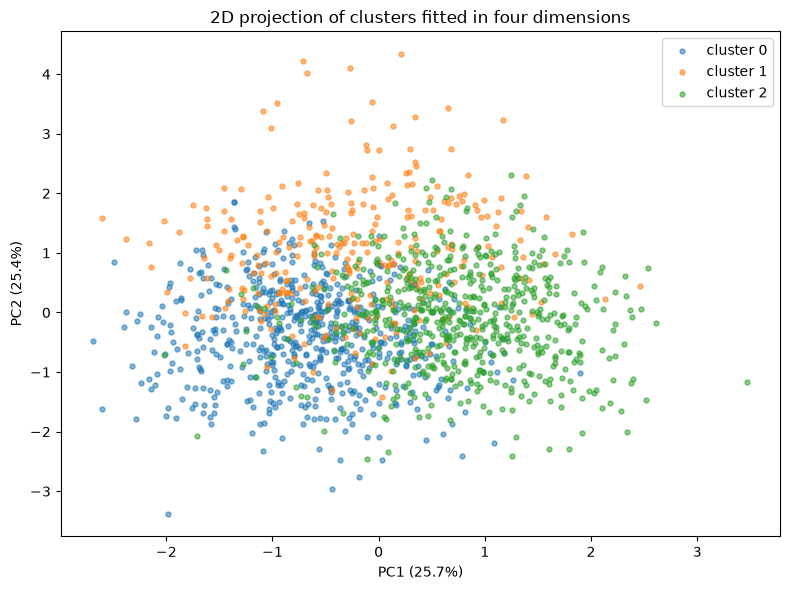

In [6]:
# TODO 4.3
pca2 = PCA(n_components=2, svd_solver="full")
projection = pca2.fit_transform(Z)
reconstructed = pca2.inverse_transform(projection)
reconstruction_mse = np.mean((Z - reconstructed) ** 2)
print("2D retained variance:", pca2.explained_variance_ratio_.sum())
print("2D reconstruction MSE in Z:", reconstruction_mse)
fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(chosen_k):
    mask = labels == cluster_id
    ax.scatter(projection[mask, 0], projection[mask, 1], s=13, alpha=0.55, label=f"cluster {cluster_id}")
ax.set(xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})",
       ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})",
       title="2D projection of clusters fitted in four dimensions")
ax.legend()
plt.tight_layout()
plt.show()
assert projection.shape == (1500, 2)
assert np.isfinite(reconstruction_mse) and reconstruction_mse >= 0

**Write 4:** how much variance does the plot retain? Does overlap in 2D prove that clusters are identical in 4D? Does PCA optimize silhouette or label separation?

**Answer:**
1. **Variance Retained in 2D:**
   - The 2D projection retains **51.04%** of the total variance: $\text{PC1} = 25.69\%$ and $\text{PC2} = 25.35\%$.
   - Nearly half (**48.96%**) of the multidimensional variance is lost in this 2D view, resulting in a reconstruction MSE of **0.4896** in standardized $Z$-space.
   - Furthermore, all 4 standardized features have roughly equal explained variance ratios (~25.7%, 25.4%, 25.0%, 24.0%), revealing that the features are nearly uncorrelated/orthogonal. As a consequence, PCA cannot reduce dimensionality without a proportional loss of information, which is why capturing $\ge 95\%$ variance requires all 4 components ($n95 = 4$).
2. **Does overlap in 2D prove that clusters are identical in 4D?**
   - **No.** Projecting 4D data onto 2 principal components is a lossy many-to-one linear transformation.
   - Points that appear overlapping in 2D may be clearly separated along the orthogonal 3rd and 4th principal components that hold the discarded 49% variance. Apparent overlap in 2D is a visual projection artifact of collapsing dimensions.
3. **Does PCA optimize silhouette or label separation?**
   - **No.** PCA is an unsupervised, linear dimension reduction technique that maximizes total projected variance ($\max \mathrm{Var}(Zw)$).
   - PCA has no mechanism to consider cluster assignments, cluster centers, or silhouette scores (which measure within-cluster tightness versus between-cluster distance). Directions of maximum total variance do not necessarily correspond to directions of optimal cluster separability.

## Stretch — When cluster shape defeats K-means (optional)
Generate `make_moons(n_samples=500, noise=0.06, random_state=42)`. Compare K-means k=2
with DBSCAN `eps=0.2, min_samples=5`. Plot partitions with matching axes.
Use synthetic truth only to compute ARI **after fitting**, never to choose eps.
DBSCAN label −1 means noise, not a customer segment.

KMeans (k=2) noise rows: 0
DBSCAN (eps=0.2) noise rows: 0


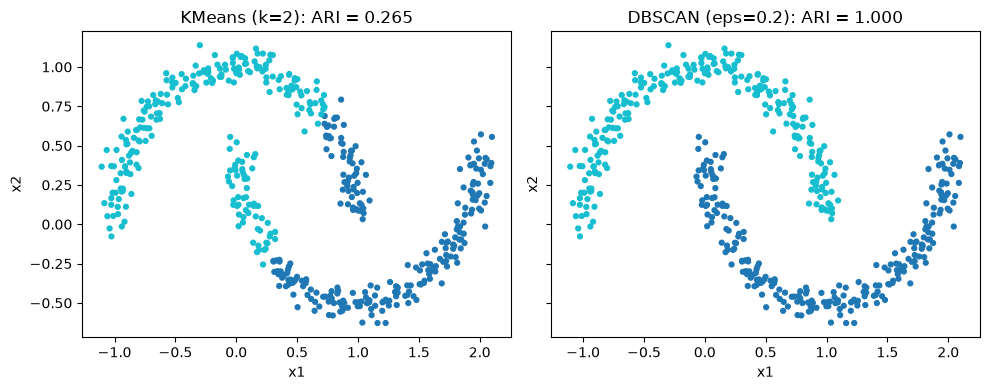

In [7]:
# TODO — optional stretch
moons, truth = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)
moon_models = {
    "KMeans (k=2)": KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE),
    "DBSCAN (eps=0.2)": DBSCAN(eps=0.2, min_samples=5)
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, (name, estimator) in zip(axes, moon_models.items()):
    assigned = estimator.fit_predict(moons)
    ax.scatter(moons[:, 0], moons[:, 1], c=assigned, cmap="tab10", s=12)
    ax.set(title=f"{name}: ARI = {adjusted_rand_score(truth, assigned):.3f}", xlabel="x1", ylabel="x2")
    print(name, "noise rows:", int((assigned == -1).sum()))
plt.tight_layout()
plt.show()

## Before submitting
- [x] Complete all four core tasks; remove remaining `...` and `TODO` from required code.
- [x] Answer all four written sections using evidence from your own run.
- [x] Give figures titles, axis labels and legends where needed; retain tables and outputs.
- [x] **Restart & Run All** passes; use seed 42 except in the specified alternate-seed experiment.
- [x] If skipping the stretch, delete its unfinished code cell before Run All and note “not attempted”.
- [x] Rename the notebook with your student ID and submit before leaving the room.